# Consumer Loan Default Analysis — Lending Club 2007–2011

**Author:** Muhammad Ahsan · **Tools:** SQL (SQLite), Python (pandas, scikit-learn, statsmodels, matplotlib)

**Business question.** A consumer lender wants to know *which borrowers default* and whether it can predict default risk at the point of application well enough to set approval cut-offs.

**What this notebook does**
1. Builds a clean loan table from the raw Lending Club file with SQL.
2. Measures how default rates move with **loan grade, income and debt-to-income (DTI)**.
3. Fits a **logistic regression** that predicts the probability of default, trained on 2007–2010 loans and tested on 2011 loans it has never seen.
4. Translates the model into a lending decision: how much a cut-off on predicted risk would lower the default rate of approved loans.

## 1. Setup and data pipeline

The raw file (`LoanStats3a.csv`, 42,535 loans) is staged in SQLite, then `sql/01_clean_loans.sql` types, filters and bands it.

**Population:** 36-month loans that met Lending Club's credit policy and reached a final outcome (Fully Paid or Charged Off). All 36-month loans had matured by the data cut-off (mid-2015), so no outcome is missing. 60-month loans are left out because about a third were still open at the cut-off, which would distort their default rate.

**Target:** `is_default = 1` when the loan was **Charged Off**.

In [1]:
import sqlite3, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from chart_style import apply_style, subtitle, source_note, pct_axis, BLUE, ORANGE, GRAY, INK, INK_2, SEQ_BLUES

apply_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

DB = ROOT / "data" / "lending_club.db"
if not DB.exists():
    # Rebuild the database from the raw file (python src/download_data.py first)
    import build_database; build_database.main()
con = sqlite3.connect(DB)

def run_sql(name: str) -> pd.DataFrame:
    """Run one of the saved queries in /sql and return the result."""
    return pd.read_sql((ROOT / "sql" / name).read_text(), con)

print(pd.read_sql("SELECT COUNT(*) AS raw_rows FROM loans_raw", con).to_string(index=False))
print(pd.read_sql("SELECT COUNT(*) AS clean_loans, SUM(is_default) AS defaults FROM loans", con).to_string(index=False))

 raw_rows
    42538
 clean_loans  defaults
       29085      3222


## 2. Portfolio overview

In [2]:
overview = run_sql("02_portfolio_overview.sql")
overview.T.rename(columns={0: "value"})

,value
loans,29085.00
funded_musd,275.40
defaults,3222.00
default_rate_pct,11.10
avg_int_rate_pct,11.00
principal_loss_musd,16.80
loss_rate_pct_of_funded,6.11
loss_severity_pct,56.40


Roughly **1 in 9** completed 36-month loans was charged off. When a loan defaults, the lender loses a little over half of the principal on average (loss severity), which works out to about 6% of all money lent.

## 3. What drives default?
### 3.1 Loan grade

,grade,loans,share_of_loans_pct,cumulative_share_pct,defaults,default_rate_pct,avg_int_rate_pct,loss_rate_pct_of_funded,default_rate_vs_grade_a
0,A,9650,33.2,33.2,565,5.9,7.33,2.73,1.0
1,B,9328,32.1,65.3,983,10.5,11.00,5.40,1.8
2,C,5746,19.8,85.0,842,14.7,13.47,8.15,2.5
3,D,3227,11.1,96.1,579,17.9,15.36,9.60,3.1
4,E,868,3.0,99.1,176,20.3,16.96,11.54,3.5
5,F,211,0.7,99.8,56,26.5,18.58,17.91,4.5
6,G,55,0.2,100.0,21,38.2,20.27,22.51,6.5


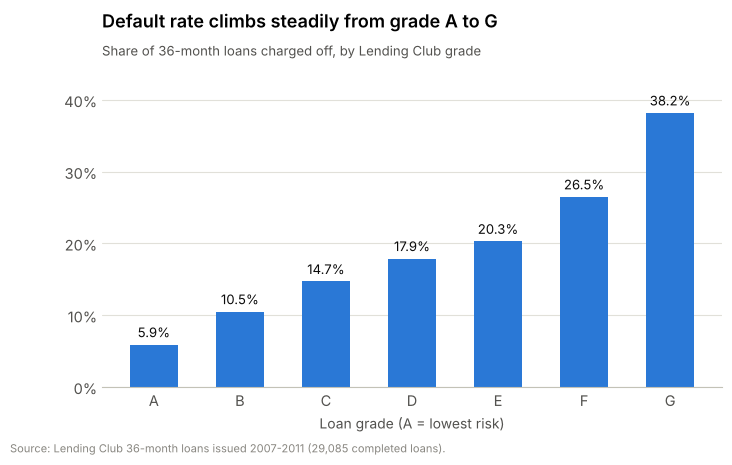

In [3]:
grade = run_sql("03_default_by_grade.sql")
display(grade)

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(grade["grade"], grade["default_rate_pct"], width=0.55, color=BLUE)
for b, v in zip(bars, grade["default_rate_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.1f}%", ha="center", va="bottom", fontsize=9.5, color=INK)
pct_axis(ax)
ax.set_ylim(0, grade["default_rate_pct"].max() * 1.18)
ax.set_title("Default rate climbs steadily from grade A to G", pad=26)
subtitle(ax, "Share of 36-month loans charged off, by Lending Club grade")
ax.set_xlabel("Loan grade (A = lowest risk)")
source_note(fig)
fig.savefig(FIG / "01_default_rate_by_grade.png")
plt.show()

**Finding.** Grade is the single strongest signal: default rates rise from **5.9% in grade A to 17.9% in grade D and 38% in grade G** — about 6.5× grade A. Interest rates rise with grade (7.3% → 20.3%), and so does the share of principal lost to defaults (2.7% → 22.5% of the amount lent).

### 3.2 Income

,income_range,loans,default_rate_pct,avg_loan_amnt,avg_loan_to_income_pct,avg_int_rate_pct
0,<$25K,1970,16.9,4534.0,24.0,11.25
1,$25-50K,9440,13.1,7452.0,20.0,10.99
2,$50-75K,8827,10.4,9662.0,16.1,10.91
3,$75-100K,4585,8.9,11775.0,14.0,10.94
4,$100-150K,3046,7.4,13383.0,11.5,11.03
5,$150K+,1217,8.2,16139.0,8.3,11.53


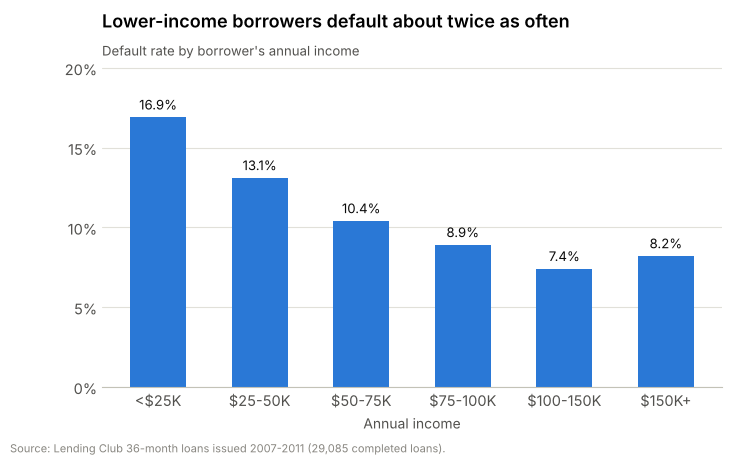

In [4]:
income = run_sql("04_default_by_income_band.sql")
display(income)

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(income["income_range"], income["default_rate_pct"], width=0.55, color=BLUE)
for b, v in zip(bars, income["default_rate_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}%", ha="center", va="bottom", fontsize=9.5, color=INK)
pct_axis(ax)
ax.set_ylim(0, income["default_rate_pct"].max() * 1.2)
ax.set_title("Lower-income borrowers default about twice as often", pad=26)
subtitle(ax, "Default rate by borrower's annual income")
ax.set_xlabel("Annual income")
source_note(fig)
fig.savefig(FIG / "02_default_rate_by_income.png")
plt.show()

**Finding.** Default risk falls as income rises, from **16.9% under \$25K to about 7–8% above \$100K**. Lower-income borrowers also take loans that are larger relative to their income (24% of annual income vs. 8% for \$150K+), so the loan is a heavier burden.

### 3.3 Debt-to-income ratio (DTI)

,dti_range,loans,default_rate_pct,avg_int_rate_pct,avg_revol_util_pct
0,0-5%,4079,9.7,10.38,29.9
1,5-10%,6174,10.1,10.75,43.9
2,10-15%,7205,10.8,11.06,49.4
3,15-20%,6473,12.1,11.35,53.6
4,20%+,5154,12.5,11.29,56.1


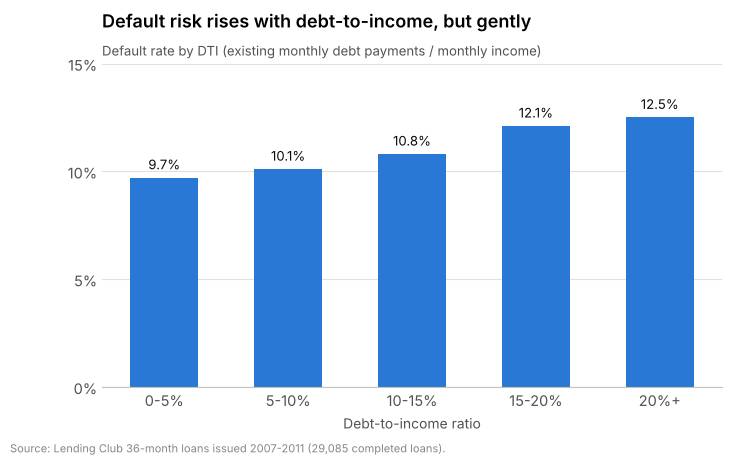

In [5]:
dti = run_sql("05_default_by_dti_band.sql")
display(dti)

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(dti["dti_range"], dti["default_rate_pct"], width=0.55, color=BLUE)
for b, v in zip(bars, dti["default_rate_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.25, f"{v:.1f}%", ha="center", va="bottom", fontsize=9.5, color=INK)
pct_axis(ax)
ax.set_ylim(0, dti["default_rate_pct"].max() * 1.2)
ax.set_title("Default risk rises with debt-to-income, but gently", pad=26)
subtitle(ax, "Default rate by DTI (existing monthly debt payments / monthly income)")
ax.set_xlabel("Debt-to-income ratio")
source_note(fig)
fig.savefig(FIG / "03_default_rate_by_dti.png")
plt.show()

### 3.4 Does DTI still matter once grade is known?

,0-5%,5-10%,10-15%,15-20%,20%+,loans
grade,,,,,,
A,4.4,5.3,5.4,7.0,7.9,9650
B,10.5,9.2,9.9,11.3,11.9,9328
C,15.1,13.0,14.4,14.8,16.2,5746
D,16.6,19.0,18.8,17.2,17.4,3227
E,24.1,24.0,21.4,19.9,12.7,868
F,NaN,NaN,22.0,NaN,NaN,211
G,NaN,NaN,NaN,NaN,NaN,55


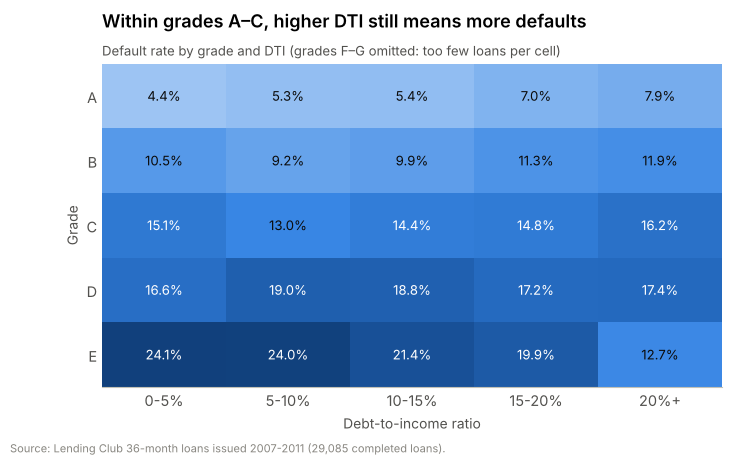

In [6]:
matrix = run_sql("06_grade_by_dti_matrix.sql").set_index("grade")
display(matrix)

heat = matrix.drop(columns="loans").loc[["A", "B", "C", "D", "E"]]
fig, ax = plt.subplots(figsize=(8, 4.2))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blues", SEQ_BLUES)
im = ax.imshow(heat.values, cmap=cmap, aspect="auto", vmin=0, vmax=26)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9.5,
                    color="white" if v > 13 else INK)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
ax.set_xlabel("Debt-to-income ratio")
ax.set_ylabel("Grade")
ax.set_title("Within grades A–C, higher DTI still means more defaults", pad=26)
subtitle(ax, "Default rate by grade and DTI (grades F–G omitted: too few loans per cell)")
source_note(fig)
fig.savefig(FIG / "04_grade_by_dti_heatmap.png")
plt.show()

**Finding.** DTI adds information *within* the prime grades: grade A loans with DTI above 20% default at **7.9% vs. 4.4%** for DTI under 5%. In grades D–E the pattern disappears — those borrowers were already priced as high-risk, and DTI was likely part of why they received the lower grade.

### 3.5 Loan purpose and vintage

In [7]:
purpose = run_sql("07_default_by_purpose.sql")
display(purpose)
vintage = run_sql("08_vintage_default_rates.sql")
display(vintage)

,purpose,loans,default_rate_pct,avg_int_rate_pct
0,small business,1238,21.7,11.84
1,educational,309,15.9,11.50
2,moving,483,15.3,11.01
3,medical,528,13.4,10.61
4,other,3136,13.2,11.05
5,other (small groups),336,12.2,10.75
6,vacation,320,11.6,10.35
7,debt consolidation,13126,11.2,11.34
8,home improvement,2079,9.9,10.22
9,car,988,8.3,9.51


,issue_year,loans,default_rate_pct,avg_int_rate_pct,avg_annual_inc,avg_dti
0,2007,251,17.9,10.32,72263.0,10.3
1,2008,1562,15.8,11.16,65120.0,12.0
2,2009,4715,12.6,12.19,68101.0,12.4
3,2010,8463,9.9,11.09,67801.0,12.7
4,2011,14094,10.6,10.55,66609.0,13.5


**Finding.** **Small-business loans default at 21.7%**, roughly double the book average, while credit-card refinancing and major purchases are the safest purposes (about 8%). Default rates improved from the 2007–2008 vintages (credit-crisis era) to 2010–2011, which matters for the model: it is tested on 2011, a calmer year than much of its training data.

## 4. Predicting default — logistic regression

**Design choices**
- **Out-of-time test.** Train on loans issued **2007–2010**, test on **2011** loans. This mimics real use: a model built on past loans scoring new applicants.
- **No leakage.** Only information available at application is used. Payment history, recoveries and anything recorded after the loan was issued are excluded.
- **Interest rate excluded.** Lending Club sets the rate from the grade, so including both would double-count the same information.
- **Benchmark.** A grade-only model shows how much the extra borrower data adds beyond Lending Club's own grade.

In [8]:
df = pd.read_sql("SELECT * FROM loans", con)

# Group rare purposes so every category has enough loans to estimate
counts = df["purpose"].value_counts()
df["purpose_grp"] = np.where(df["purpose"].map(counts) >= 300, df["purpose"], "other")
df["log_annual_inc"] = np.log(df["annual_inc"])
df["emp_length_missing"] = df["emp_length_yrs"].isna().astype(int)
df["has_pub_rec"] = (df["pub_rec"] > 0).astype(int)
df["has_delinq_2yrs"] = (df["delinq_2yrs"] > 0).astype(int)

NUMERIC = ["log_annual_inc", "dti", "loan_to_income", "revol_util", "inq_last_6mths",
           "credit_history_yrs", "emp_length_yrs", "open_acc", "total_acc"]
BINARY = ["has_pub_rec", "has_delinq_2yrs", "emp_length_missing"]
CATEGORICAL = ["grade", "home_ownership", "income_verified", "purpose_grp"]
TARGET = "is_default"

train = df[df["issue_year"] <= 2010].copy()
test = df[df["issue_year"] == 2011].copy()
pd.DataFrame({
    "loans": [len(train), len(test)],
    "default_rate_pct": [100 * train[TARGET].mean(), 100 * test[TARGET].mean()],
}, index=["train (2007-2010)", "test (2011)"]).round(2)

,loans,default_rate_pct
train (2007-2010),14991,11.53
test (2011),14094,10.60


In [9]:
def make_model(numeric, binary, categorical):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("bin", "passthrough", binary),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
    ])
    return Pipeline([("prep", pre), ("logit", LogisticRegression(max_iter=2000, C=1.0))])

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return np.max(tpr - fpr)

models = {
    "Grade only (benchmark)": make_model([], [], ["grade"]),
    "Full model": make_model(NUMERIC, BINARY, CATEGORICAL),
}
results, preds = [], {}
for name, m in models.items():
    m.fit(train, train[TARGET])
    p_train = m.predict_proba(train)[:, 1]
    p_test = m.predict_proba(test)[:, 1]
    preds[name] = p_test
    results.append({
        "model": name,
        "train_AUC": roc_auc_score(train[TARGET], p_train),
        "test_AUC": roc_auc_score(test[TARGET], p_test),
        "test_Gini": 2 * roc_auc_score(test[TARGET], p_test) - 1,
        "test_KS": ks_stat(test[TARGET], p_test),
        "test_Brier": brier_score_loss(test[TARGET], p_test),
    })
perf = pd.DataFrame(results).set_index("model").round(3)
perf

,train_AUC,test_AUC,test_Gini,test_KS,test_Brier
model,,,,,
Grade only (benchmark),0.635,0.621,0.243,0.178,0.093
Full model,0.686,0.674,0.348,0.254,0.091


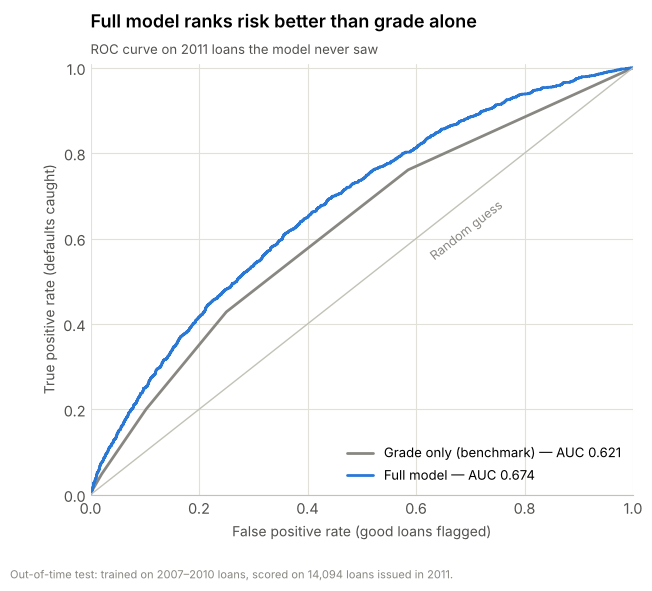

In [10]:
fig, ax = plt.subplots(figsize=(7, 5.6))
ax.grid(True, axis="both")
colors = {"Grade only (benchmark)": GRAY, "Full model": BLUE}
for name, p in preds.items():
    fpr, tpr, _ = roc_curve(test[TARGET], p)
    auc = roc_auc_score(test[TARGET], p)
    ax.plot(fpr, tpr, color=colors[name], label=f"{name} — AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1)
ax.text(0.62, 0.55, "Random guess", color=GRAY, fontsize=9, rotation=38)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_xlabel("False positive rate (good loans flagged)")
ax.set_ylabel("True positive rate (defaults caught)")
ax.set_title("Full model ranks risk better than grade alone", pad=26)
subtitle(ax, "ROC curve on 2011 loans the model never saw")
ax.legend(loc="lower right")
source_note(fig, "Out-of-time test: trained on 2007–2010 loans, scored on 14,094 loans issued in 2011.")
fig.savefig(FIG / "05_roc_curve.png")
plt.show()

**Result.** On unseen 2011 loans the full model scores an **AUC of 0.674 (Gini 0.35, KS 0.25)** versus **0.621** for grade alone. Train and test AUC are close (0.686 vs. 0.674), so the model holds up on a new year of loans rather than memorizing the old ones. The lift over grade is the key point: income, credit inquiries, loan size relative to income and loan purpose carry risk information that Lending Club's grade had not fully priced.

### 4.1 Which factors drive the predicted risk?
Statsmodels gives standard errors and p-values. Numeric features are standardized, so each odds ratio is the change in default odds for a **one standard deviation** increase.

In [11]:
X_tr = models["Full model"].named_steps["prep"].transform(train)
feat_names = (NUMERIC + BINARY +
              list(models["Full model"].named_steps["prep"].named_transformers_["cat"].get_feature_names_out(CATEGORICAL)))
X_tr = pd.DataFrame(X_tr.toarray() if hasattr(X_tr, "toarray") else X_tr, columns=feat_names, index=train.index)
logit = sm.Logit(train[TARGET], sm.add_constant(X_tr)).fit(disp=False)

coef = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ci_low": np.exp(logit.conf_int()[0]),
    "ci_high": np.exp(logit.conf_int()[1]),
    "p_value": logit.pvalues,
}).drop("const")
coef["significant_5pct"] = coef["p_value"] < 0.05
print(f"Pseudo R-squared: {logit.prsquared:.3f}   Observations: {int(logit.nobs):,}")
coef.sort_values("odds_ratio", ascending=False).round(3)

Pseudo R-squared: 0.064   Observations: 14,991


,odds_ratio,ci_low,ci_high,p_value,significant_5pct
grade_G,6.385,3.304,12.339,0.000,True
grade_F,5.352,3.561,8.042,0.000,True
grade_E,3.532,2.673,4.666,0.000,True
grade_D,3.323,2.693,4.101,0.000,True
grade_C,2.570,2.124,3.111,0.000,True
purpose_grp_small_business,2.094,1.417,3.093,0.000,True
emp_length_missing,1.947,1.403,2.701,0.000,True
grade_B,1.936,1.620,2.313,0.000,True
purpose_grp_vacation,1.595,0.861,2.956,0.138,False
has_pub_rec,1.569,1.293,1.904,0.000,True


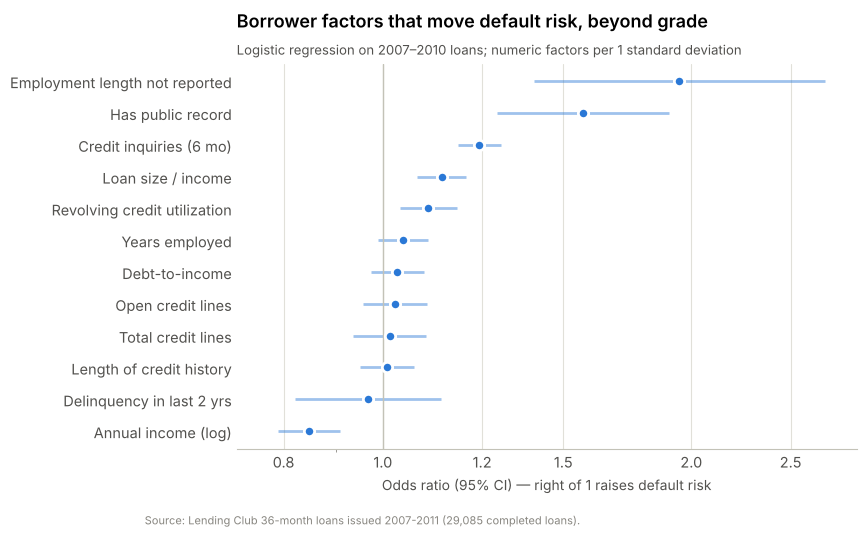

In [12]:
labels = {
    "log_annual_inc": "Annual income (log)", "dti": "Debt-to-income", "loan_to_income": "Loan size / income",
    "revol_util": "Revolving credit utilization", "inq_last_6mths": "Credit inquiries (6 mo)",
    "credit_history_yrs": "Length of credit history", "emp_length_yrs": "Years employed",
    "open_acc": "Open credit lines", "total_acc": "Total credit lines",
    "has_pub_rec": "Has public record", "has_delinq_2yrs": "Delinquency in last 2 yrs",
    "emp_length_missing": "Employment length not reported",
}
num_or = coef.loc[NUMERIC + BINARY].copy()
num_or["label"] = num_or.index.map(labels)
num_or = num_or.sort_values("odds_ratio")

fig, ax = plt.subplots(figsize=(8, 5))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
y = np.arange(len(num_or))
ax.hlines(y, num_or["ci_low"], num_or["ci_high"], color=BLUE, linewidth=2, alpha=0.45)
ax.scatter(num_or["odds_ratio"], y, s=55, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
ax.axvline(1, color="#c3c2b7", linewidth=1)
ax.set_yticks(y, num_or["label"])
ax.set_xlabel("Odds ratio (95% CI) — right of 1 raises default risk")
ax.set_title("Borrower factors that move default risk, beyond grade", pad=26)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f")); ax.xaxis.set_minor_formatter(mtick.NullFormatter()); ax.set_xticks([0.8, 1.0, 1.25, 1.5, 2.0, 2.5]); ax.set_xlim(0.72, 2.9)
subtitle(ax, "Logistic regression on 2007–2010 loans; numeric factors per 1 standard deviation")
source_note(fig)
fig.savefig(FIG / "06_odds_ratios.png")
plt.show()

### 4.2 Does the model separate risky from safe loans?
Split the 2011 test loans into ten equal groups by predicted risk and compare predicted with actual default rates.

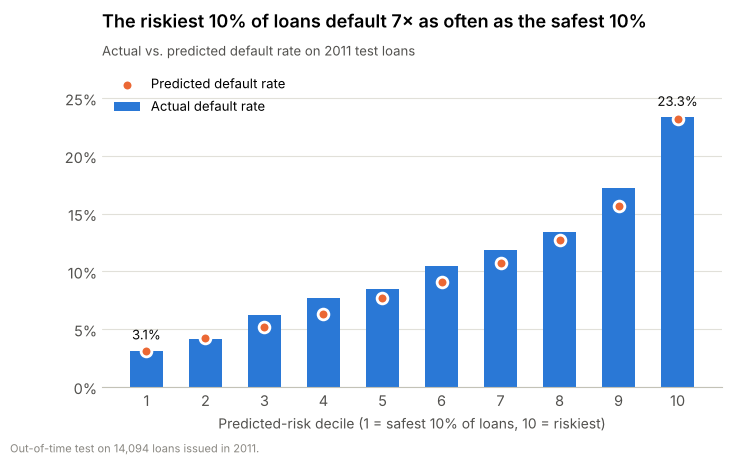

In [13]:
t = test[[TARGET, "funded_amnt", "principal_loss", "grade"]].copy()
t["pd_full"] = preds["Full model"]
t["pd_grade"] = preds["Grade only (benchmark)"]
t["decile"] = pd.qcut(t["pd_full"].rank(method="first"), 10, labels=range(1, 11))
dec = t.groupby("decile", observed=True).agg(
    loans=(TARGET, "size"),
    predicted_pct=("pd_full", lambda s: 100 * s.mean()),
    actual_pct=(TARGET, lambda s: 100 * s.mean()),
).round(2)
dec

fig, ax = plt.subplots(figsize=(8, 4.2))
x = dec.index.astype(int)
ax.bar(x, dec["actual_pct"], width=0.55, color=BLUE, label="Actual default rate")
ax.scatter(x, dec["predicted_pct"], s=60, color=ORANGE, edgecolor="white", linewidth=2, zorder=3, label="Predicted default rate")
ax.text(x[-1], dec["actual_pct"].iloc[-1] + 1.0, f"{dec['actual_pct'].iloc[-1]:.1f}%", ha="center", fontsize=9.5, color=INK)
ax.text(x[0], dec["actual_pct"].iloc[0] + 1.0, f"{dec['actual_pct'].iloc[0]:.1f}%", ha="center", fontsize=9.5, color=INK)
ax.set_xticks(x)
pct_axis(ax)
ax.set_ylim(0, dec[["actual_pct", "predicted_pct"]].max().max() * 1.2)
ax.set_xlabel("Predicted-risk decile (1 = safest 10% of loans, 10 = riskiest)")
ratio = dec["actual_pct"].iloc[-1] / dec["actual_pct"].iloc[0]
ax.set_title(f"The riskiest 10% of loans default {ratio:.0f}× as often as the safest 10%", pad=26)
subtitle(ax, "Actual vs. predicted default rate on 2011 test loans")
ax.legend(loc="upper left")
source_note(fig, "Out-of-time test on 14,094 loans issued in 2011.")
fig.savefig(FIG / "07_risk_deciles.png")
plt.show()

## 5. Business application — setting an approval cut-off

If the lender had declined the riskiest share of 2011 applicants, how would the approved book have looked? The table compares ranking applicants by the **full model** with ranking by **grade alone**.

In [14]:
def cutoff_table(t, score_col, decline_shares=(0.05, 0.10, 0.15, 0.20)):
    rows = []
    base_dr = t[TARGET].mean()
    total_def = t[TARGET].sum()
    total_loss = t["principal_loss"].sum()
    # tiny random tie-break so grade-only scores (7 distinct values) can be cut at any share
    rng = np.random.default_rng(42)
    order = (t[score_col] + rng.uniform(0, 1e-9, len(t))).rank(ascending=False, method="first")
    for s in decline_shares:
        declined = order <= s * len(t)
        appr = t[~declined]
        rows.append({
            "decline_share": f"{s:.0%}",
            "approved_default_rate_pct": 100 * appr[TARGET].mean(),
            "default_rate_reduction_pct_pts": 100 * (base_dr - appr[TARGET].mean()),
            "defaults_avoided_pct": 100 * t.loc[declined, TARGET].sum() / total_def,
            "principal_loss_avoided_pct": 100 * t.loc[declined, "principal_loss"].sum() / total_loss,
            "good_loans_declined": int((declined & (t[TARGET] == 0)).sum()),
        })
    return pd.DataFrame(rows).set_index("decline_share").round(2)

print(f"2011 baseline default rate: {100 * t[TARGET].mean():.2f}%  |  principal lost: ${t['principal_loss'].sum()/1e6:.1f}M")
cut_full = cutoff_table(t, "pd_full")
cut_grade = cutoff_table(t, "pd_grade")
display(cut_full.assign(model="Full model"))
display(cut_grade.assign(model="Grade only"))

2011 baseline default rate: 10.60%  |  principal lost: $6.9M


,approved_default_rate_pct,default_rate_reduction_pct_pts,defaults_avoided_pct,principal_loss_avoided_pct,good_loans_declined,model
decline_share,,,,,,
5%,9.79,0.81,12.25,14.56,521,Full model
10%,9.18,1.42,22.02,25.54,1080,Full model
15%,8.66,1.94,30.59,34.27,1657,Full model
20%,8.18,2.42,38.29,42.59,2246,Full model


,approved_default_rate_pct,default_rate_reduction_pct_pts,defaults_avoided_pct,principal_loss_avoided_pct,good_loans_declined,model
decline_share,,,,,,
5%,10.06,0.54,9.84,11.93,557,Grade only
10%,9.65,0.95,18.07,21.39,1139,Grade only
15%,9.23,1.37,25.97,29.85,1726,Grade only
20%,8.99,1.61,32.13,35.58,2338,Grade only


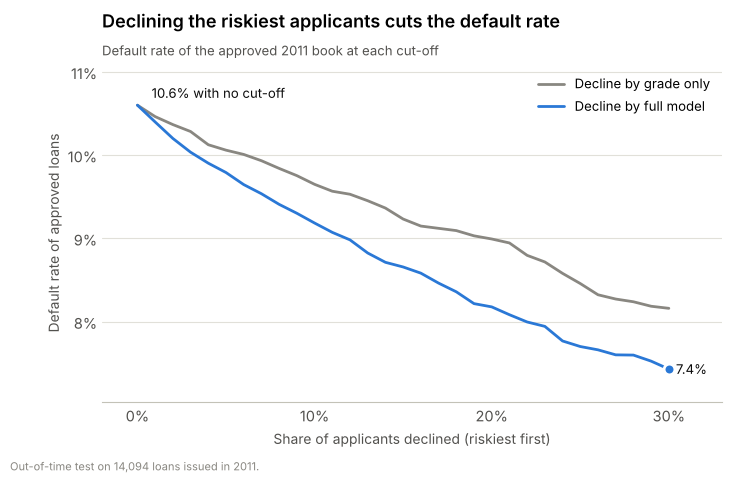

In [15]:
shares = np.linspace(0, 0.30, 31)
def approved_dr_curve(score):
    rng = np.random.default_rng(42)
    order = (t[score] + rng.uniform(0, 1e-9, len(t))).rank(ascending=False, method="first")
    return [100 * t.loc[order > s * len(t), TARGET].mean() for s in shares]

curve_full = approved_dr_curve("pd_full")
curve_grade = approved_dr_curve("pd_grade")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(100 * shares, curve_grade, color=GRAY, label="Decline by grade only")
ax.plot(100 * shares, curve_full, color=BLUE, label="Decline by full model")
ax.scatter([100 * shares[-1]], [curve_full[-1]], s=60, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
ax.text(100 * shares[-1] + 0.4, curve_full[-1], f"{curve_full[-1]:.1f}%", va="center", fontsize=9.5, color=INK)
ax.text(100 * shares[0] + 0.8, curve_full[0] + 0.05, f"{curve_full[0]:.1f}% with no cut-off", va="bottom", ha="left", fontsize=9.5, color=INK)
pct_axis(ax, "x"); pct_axis(ax)
ax.set_xlim(-2, 33)
ax.set_ylim(min(curve_full) - 0.4, curve_full[0] + 0.5)
ax.set_xlabel("Share of applicants declined (riskiest first)")
ax.set_ylabel("Default rate of approved loans")
ax.set_title("Declining the riskiest applicants cuts the default rate", pad=26)
subtitle(ax, "Default rate of the approved 2011 book at each cut-off")
ax.legend(loc="upper right")
source_note(fig, "Out-of-time test on 14,094 loans issued in 2011.")
fig.savefig(FIG / "08_cutoff_tradeoff.png")
plt.show()

## 6. Key findings

The numbers below are pulled from the analysis above.

In [16]:
g = 100 * df.groupby("grade")[TARGET].mean()
inc = 100 * df.groupby(df["income_band"].str[3:])[TARGET].mean()
fp, gp = perf.loc["Full model"], perf.loc["Grade only (benchmark)"]
c10f, c10g = cut_full.loc["10%"], cut_grade.loc["10%"]
summary = f"""
- Book: {int(overview.loans[0]):,} completed 36-month loans, {overview.default_rate_pct[0]:.1f}% charged off, {overview.loss_severity_pct[0]:.0f}% of principal lost on a default.
- Grade: default rate rises from {g['A']:.1f}% (A) to {g['D']:.1f}% (D) and {g['G']:.1f}% (G).
- Income: {inc['<$25K']:.1f}% default under $25K vs {inc['$100-150K']:.1f}% at $100-150K.
- DTI: within grade A, default rises from {matrix.loc['A','0-5%']:.1f}% (DTI <5%) to {matrix.loc['A','20%+']:.1f}% (DTI 20%+).
- Model: test AUC {fp.test_AUC:.3f} (Gini {fp.test_Gini:.3f}, KS {fp.test_KS:.3f}) vs {gp.test_AUC:.3f} for grade alone.
- Cut-off: declining the riskiest 10% by the model avoids {c10f.defaults_avoided_pct:.1f}% of defaults and {c10f.principal_loss_avoided_pct:.1f}% of principal losses (grade only: {c10g.defaults_avoided_pct:.1f}% / {c10g.principal_loss_avoided_pct:.1f}%), lowering the approved default rate from {100*t[TARGET].mean():.1f}% to {c10f.approved_default_rate_pct:.1f}%.
"""
print(summary)
(ROOT / "reports" / "key_findings.txt").write_text(summary.strip() + "\n")
perf.to_csv(ROOT / "reports" / "model_performance.csv")
coef.round(4).to_csv(ROOT / "reports" / "odds_ratios.csv")
cut_full.to_csv(ROOT / "reports" / "cutoff_analysis_full_model.csv")


- Book: 29,085 completed 36-month loans, 11.1% charged off, 56% of principal lost on a default.
- Grade: default rate rises from 5.9% (A) to 17.9% (D) and 38.2% (G).
- Income: 16.9% default under $25K vs 7.4% at $100-150K.
- DTI: within grade A, default rises from 4.4% (DTI <5%) to 7.9% (DTI 20%+).
- Model: test AUC 0.674 (Gini 0.348, KS 0.254) vs 0.621 for grade alone.
- Cut-off: declining the riskiest 10% by the model avoids 22.0% of defaults and 25.5% of principal losses (grade only: 18.1% / 21.4%), lowering the approved default rate from 10.6% to 9.2%.



## 7. Limitations and next steps

- **Data era.** Loans are from 2007–2011, including the credit crisis. Patterns should be re-tested on recent data before use.
- **Approved applicants only.** The data only contains loans Lending Club approved, so the model has never seen rejected applicants (reject-inference problem).
- **36-month loans only.** 60-month loans were excluded because many had not closed by the data cut-off.
- **Model choice.** Logistic regression was chosen because it is explainable and standard in credit scoring. Gradient-boosted trees could raise AUC, but at the cost of transparency.
- **Next steps:** add interest income to turn the cut-off analysis into a profit-maximizing threshold, and test calibration on a more recent vintage.